# Tugas Praktikum #2 - Pemrograman Paralel / Multithreading
## Nama:** [FATHIYA DHIYAUL IZZATY]  
## NIM:** [2411513037]

### 1. Buat simulasi rekening bank sederhana dengan saldo awal 1.000.000. Buat 10 thread yang masing-masing melakukan 10.000 kali operasi "tarik 1 lalu setor 1" (saldo -= 1; saldo += 1) tanpa lock. Jalankan dan amati apakah saldo akhir tetap 1.000.000. Ulangi dengan menambahkan threading.Lock() yang tepat, lalu bandingkan hasilnya dan jelaskan.
## JAWAB:

##### 1.A tanpa lock

In [7]:
import threading
saldo = 1000000

def transaksi_tanpa_lock():
    global saldo
    for _ in range(10000):
        # Operasi tarik 1 lalu setor 1
        saldo -= 1
        saldo += 1

threads = []
for _ in range(10):
    t = threading.Thread(target=transaksi_tanpa_lock)
    threads.append(t)
    t.start()

for t in threads:
    t.join()

print(f"Saldo Akhir (Tanpa Lock) : {saldo}")


Saldo Akhir (Tanpa Lock) : 1000000


##### 1.B Dengan lock

In [4]:
saldo_aman = 1000000
lock = threading.Lock()

def transaksi_dengan_lock():
    global saldo_aman
    for _ in range(10000):
        with lock:
            saldo_aman -= 1
            saldo_aman += 1

threads_aman = []
for _ in range(10):
    t = threading.Thread(target=transaksi_dengan_lock)
    threads_aman.append(t)
    t.start()

for t in threads_aman:
    t.join()

print(f"Saldo Akhir (Dengan Lock): {saldo_aman}")

Saldo Akhir (Dengan Lock): 1000000


##### Tanpa Lock: Saldo bisa tidak sama dengan 1.000.000 karena terjadi race condition, yaitu beberapa thread mengakses dan mengubah saldo secara bersamaan sehingga perubahan dapat saling tertimpa.
##### Dengan Lock: Saldo tetap 1.000.000 karena threading.Lock() memastikan hanya satu thread yang dapat mengubah saldo dalam satu waktu.

### 2. Modifikasi contoh queue.Queue pada bagian 3 agar memiliki 1 producer dan 3 consumer yang berjalan bersamaan. Pastikan seluruh consumer berhenti dengan baik ketika producer selesai (hint: perhatikan cara sinyal None diteruskan pada contoh di atas, kalian perlu menyesuaikannya untuk 3 consumer).
## JAWAB:

In [3]:
import queue
import threading
import time

q = queue.Queue()
NUM_CONSUMERS = 3

def producer():
    for i in range(10):
        q.put(f"Data-{i}")
        time.sleep(0.02)
    
    # Mengirim sinyal None sebanyak jumlah consumer agar seluruh consumer berhenti
    for _ in range(NUM_CONSUMERS):
        q.put(None)

def consumer(consumer_id):
    while True:
        item = q.get()
        if item is None:
            print(f"Consumer-{consumer_id} menerima sinyal None dan BERHENTI.")
            break
        print(f"Consumer-{consumer_id} memproses: {item}")
        q.task_done()

# Menjalankan Threads
t_prod = threading.Thread(target=producer)
t_prod.start()

t_cons = []
for i in range(NUM_CONSUMERS):
    t = threading.Thread(target=consumer, args=(i+1,))
    t_cons.append(t)
    t.start()

t_prod.join()
for t in t_cons:
    t.join()

print("Seluruh producer dan consumer telah selesai.")

Consumer-1 memproses: Data-0
Consumer-1 memproses: Data-1
Consumer-2 memproses: Data-2
Consumer-3 memproses: Data-3
Consumer-1 memproses: Data-4
Consumer-2 memproses: Data-5
Consumer-3 memproses: Data-6
Consumer-1 memproses: Data-7
Consumer-2 memproses: Data-8
Consumer-3 memproses: Data-9
Consumer-1 menerima sinyal None dan BERHENTI.
Consumer-2 menerima sinyal None dan BERHENTI.
Consumer-3 menerima sinyal None dan BERHENTI.
Seluruh producer dan consumer telah selesai.


### 3. Ulangi eksperimen pada bagian 6 dengan jumlah file 50 (bukan 8) dan bandingkan max_workers = 2, 4, 8, dan 16. Plot waktu eksekusi vs max_workers. Apakah menambah max_workers terus-menerus selalu mempercepat proses? Jelaskan mengapa ada titik jenuh.
## JAWAB:

max_workers =  2 | Waktu Eksekusi: 1.2794 detik
max_workers =  4 | Waktu Eksekusi: 0.6561 detik
max_workers =  8 | Waktu Eksekusi: 0.3550 detik
max_workers = 16 | Waktu Eksekusi: 0.2037 detik


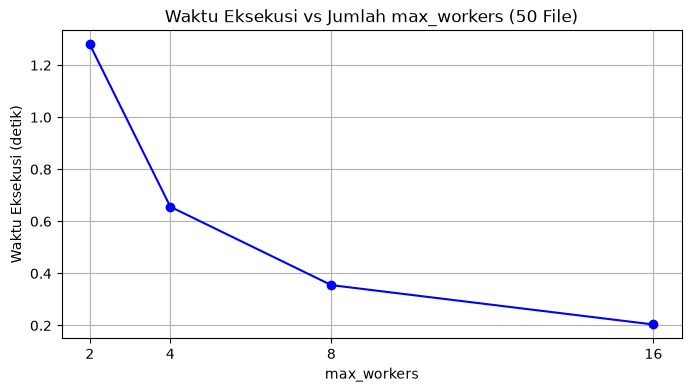

In [6]:
import concurrent.futures
import time
import matplotlib.pyplot as plt

def simulasi_proses_file(file_id):
    time.sleep(0.05)  # Simulasi tugas I/O bound
    return file_id

jumlah_file = 50
workers_list = [2, 4, 8, 16]
waktu_eksekusi = []

for max_workers in workers_list:
    start_time = time.time()
    with concurrent.futures.ThreadPoolExecutor(max_workers=max_workers) as executor:
        results = list(executor.map(simulasi_proses_file, range(jumlah_file)))
    total_time = time.time() - start_time
    waktu_eksekusi.append(total_time)
    print(f"max_workers = {max_workers:2d} | Waktu Eksekusi: {total_time:.4f} detik")

# Plot Grafik
plt.figure(figsize=(8, 4))
plt.plot(workers_list, waktu_eksekusi, marker='o', color='b', linestyle='-')
plt.title("Waktu Eksekusi vs Jumlah max_workers (50 File)")
plt.xlabel("max_workers")
plt.ylabel("Waktu Eksekusi (detik)")
plt.xticks(workers_list)
plt.grid(True)
plt.show()

##### Menambah max_workers tidak selalu mempercepat proses secara linier dan akan mencapai titik jenuh. Penyebab titik jenuh Karna:
##### 1. Keterbatasan Jumlah CPU Core: Jumlah thread paralel murni dibatasi oleh jumlah inti CPU (hardware) pada perangkat
##### 2. Semakin banyak thread yang dibuat, sistem operasi menghabiskan lebih banyak daya dan waktu untuk berganti konteks antar-thread (overhead).
##### 3. Python membatasi eksekusi instruksi bytecode agar dilakukan secara bergantian, sehingga thread tambahan tidak selalu memberikan skalabilitas tanpa batas.

### 4. Berikan satu contoh kasus nyata (di luar contoh pada notebook ini) di mana threading Python akan membantu, dan satu contoh kasus di mana threading Python tidak akan membantu dan sebaiknya menunggu materi multiprocessing (Pertemuan 3).
## JAWAB:

##### 1. Threading membantu:
##### Contohnya mengunduh beberapa file dari internet secara bersamaan. Threading dapat mengurangi waktu tunggu karena prosesnya banyak bergantung pada jaringan.
##### 2. Threading tidak membantu:
##### Contohnya perhitungan matematika yang sangat berat. Karena membutuhkan CPU tinggi, sebaiknya menggunakan multiprocessing agar pekerjaan dapat dibagi ke beberapa proses.